# Detección de fraude en transacciones financieras
## Proyecto final - Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

· **Equipo:** _[Samuel Puerta Patiño]_, _[Simón Berrio Gaviria]_, _[Juan Estiven Carmona Muñoz]_

· **Grupo:** _[5]_

· **Semestre:** _[2026-2]_

 **Dataset:** [Financial Transactions & Fraud Detection (Kaggle)](https://www.kaggle.com/datasets/greatcool/financial-transactions-and-fraud-detection-dataset)


## 1. Configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

# Scikit-Learn (módulos clave de división, preprocesamiento y evaluación)
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# PyTorch (módulos base para redes neuronales)
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Configuración visual
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Reproducibilidad global (NumPy + PyTorch)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Rutas del proyecto
DATA_PATH = Path("data/synthetic_financial_transactions.csv")
FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Guarda la figura actual en PDF (para LaTeX) y PNG (para vista previa)."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

---
# 2. Descripción del problema

## 2.1 Contexto del problema

El fraude en transacciones financieras consiste en el uso no autorizado de medios de pago, y genera pérdidas de miles de millones de dólares al año para entidades y clientes {Gostkowski2024}. Los sistemas basados en reglas manuales no escalan al volumen de transacciones ni capturan patrones no evidentes, por lo que el aprendizaje de máquina es una alternativa natural {Cherif2023}. Detectar fraude es difícil por la fuerte desproporción entre transacciones legítimas y fraudulentas, y por el solapamiento entre ambas clases {Kalid2024,DalPozzolo2018}. Un modelo de este tipo apoyaría la decisión de alertar, bloquear o enviar una transacción a revisión. Un falso negativo (fraude no detectado) suele costar más que un falso positivo (revisión innecesaria), por lo que la evaluación no puede basarse en la exactitud global. El conjunto de datos usado es sintético, de modo que los resultados describen el comportamiento de los modelos sobre estos datos y no son extrapolables directamente a un sistema real.

## 2.2 Composición de la base de datos

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Muestras: {df.shape[0]:,}  |  Variables: {df.shape[1]}")
df.head()

Muestras: 10,000  |  Variables: 11


,transaction_id,timestamp,user_id,account_type,category,amount,currency,payment_method,device_type,risk_score,is_fraud
0,TXN_100000,2025-08-26 08:02:13.821309,USR_5559,Checking,Electronics,22.920,USD,Debit Card,Desktop,36.510,0
1,TXN_100001,2025-08-26 08:24:13.821309,USR_6322,Checking,Dining,17.890,USD,Debit Card,POS Terminal,16.890,0
2,TXN_100002,2025-08-26 09:53:13.821309,USR_2845,Checking,Online Transfer,12.420,USD,Debit Card,ATM,6.680,0
3,TXN_100003,2025-08-26 10:26:13.821309,USR_9984,Savings,Groceries,28.700,USD,Credit Card,ATM,73.640,1
4,TXN_100004,2025-08-26 11:16:13.821309,USR_5988,Savings,Travel,9.270,USD,Debit Card,Desktop,42.340,0


In [3]:
# Diccionario de variables
resumen = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "faltantes": df.isna().sum(),
    "ejemplo": df.iloc[0],
})
resumen

,tipo_pandas,n_unicos,faltantes,ejemplo
transaction_id,object,10000,0,TXN_100000
timestamp,object,9921,0,2025-08-26 08:02:13.821309
user_id,object,2142,0,USR_5559
account_type,object,3,0,Checking
category,object,8,0,Electronics
amount,float64,6104,0,22.920
currency,object,1,0,USD
payment_method,object,4,0,Debit Card
device_type,object,4,0,Desktop
risk_score,float64,4811,0,36.510


In [4]:
print("Duplicados (fila completa):", df.duplicated().sum())
print("IDs de transacción duplicados:", df["transaction_id"].duplicated().sum())
print("Valores faltantes totales:", int(df.isna().sum().sum()))
print("Valores únicos de currency:", df["currency"].unique())
print("Rango temporal:", df["timestamp"].min(), "->", df["timestamp"].max())

Duplicados (fila completa): 0
IDs de transacción duplicados: 0
Valores faltantes totales: 0
Valores únicos de currency: ['USD']
Rango temporal: 2025-08-26 08:02:13.821309 -> 2026-08-26 04:30:13.821309


El conjunto contiene 10.000 transacciones de 2.142 usuarios, entre el 26 de agosto de 2025 y el 26 de agosto de 2026, descritas por 11 variables: tres identificadores (transaction_id, user_id, timestamp), cuatro categóricas (account_type, category, payment_method, device_type), dos numéricas (amount, risk_score), la moneda (currency) y la etiqueta is_fraud. No hay datos faltantes, filas duplicadas ni identificadores repetidos, por lo que no se requirió imputación. La variable currency es constante (USD) y se descartó.

La clase positiva está fuertemente desbalanceada: 126 fraudes (1,26 %) frente a 9.874 transacciones normales (98,74 %). Un clasificador que nunca predice fraude alcanzaría ≈ 98,7 % de exactitud, por eso esta métrica no se usa como criterio. Los 126 fraudes están repartidos en 124 usuarios, y solo 2 usuarios tienen más de uno. Cada usuario tiene en promedio 4,7 transacciones (máximo 18).

Variables numéricas. El monto está muy sesgado a la derecha (asimetría 5,68; mediana 27,36 USD; máximo 1.668,90). Con log(1+amount) la asimetría baja a 0,14. El monto no distingue las clases: medianas de 25,4 USD en fraudes y 27,4 en normales (Mann-Whitney, p = 0,70; AUC univariada 0,49). El risk_score sí difiere (medianas 33,3 y 26,6; p = 8,3·10⁻⁵), pero su AUC univariada es solo 0,60. La razón es que los fraudes forman dos grupos. Cerca del 24 % tiene risk_score ≥ 65, frente al 1,7 % de las transacciones normales, y el resto se parece a las normales. Una regla simple con umbral 70 captura el 23,8 % de los fraudes con una precisión del 31 %.

Variables categóricas. Ninguna asociación con el fraude es significativa (χ²: account_type p = 0,41; category p = 0,74; payment_method p = 0,78; device_type p = 0,87). Los intervalos de Wilson al 95 % de todos los niveles contienen la tasa global (1,26 %). Tampoco hay relación entre estas variables y risk_score (promedios entre 27,7 y 29,2 en todos los niveles), ni entre amount y risk_score (Spearman 0,014). En las cuatro variables el mínimo de fraudes esperados por nivel supera 5, por lo que se cumple el supuesto de la prueba χ².

Variable temporal. La tasa de fraude no varía de forma apreciable con el momento de la transacción. Dado que algunos niveles (hora, mes) tienen menos de 5 fraudes esperados, la prueba χ² clásica no es apropiada, y se empleó una prueba de permutación sobre el estadístico χ² (5.000 permutaciones). Los p-valores fueron 0,58 para la hora, 0,84 para el día de la semana y 0,38 para el mes, y 0,34 al agrupar la hora en cuatro franjas de seis horas; ninguno es significativo. Las barras con tasas altas o bajas en las figuras obedecen al escaso número de fraudes por nivel. Por ejemplo, agosto de 2025 solo tiene 154 transacciones (el registro comienza el día 26), por lo que su tasa del 2,6 % no es fiable.

### Variable objetivo y desbalance

,n,%
is_fraud,,
Normal,9874,98.740
Fraude,126,1.260


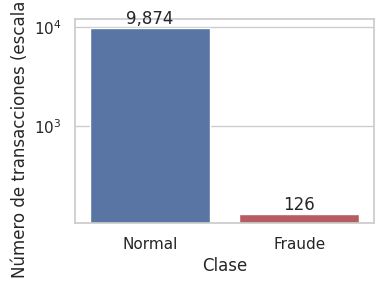

In [5]:
conteo = df["is_fraud"].value_counts().rename({0: "Normal", 1: "Fraude"})
tabla_clase = pd.DataFrame({"n": conteo, "%": 100 * conteo / len(df)})
display(tabla_clase)

fig, ax = plt.subplots(figsize=(4, 3))
sns.barplot(x=tabla_clase.index, y=tabla_clase["n"], ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de transacciones (escala log)")
for i, v in enumerate(tabla_clase["n"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
savefig("fig_desbalance")
plt.show()

### Variables numéricas: `amount` y `risk_score`

In [6]:
display(df[["amount", "risk_score"]].describe().T)
display(df.groupby("is_fraud")[["amount", "risk_score"]].describe().T)
print("Asimetría (skew) de amount:", round(df["amount"].skew(), 2),
      "| de log1p(amount):", round(np.log1p(df["amount"]).skew(), 2))

,count,mean,std,min,25%,50%,75%,max
amount,"10,000.000",49.637,72.345,1.500,12.880,27.355,57.595,"1,668.900"
risk_score,"10,000.000",28.660,15.810,0.310,16.270,26.620,39.212,89.240


is_fraud                 0       1
amount     count 9,874.000 126.000
           mean     49.583  53.882
           std      72.195  83.435
           min       1.500   1.500
           25%      12.910  11.672
           50%      27.370  25.395
           75%      57.710  54.445
           max   1,668.900 508.460
risk_score count 9,874.000 126.000
           mean     28.534  38.559
           std      15.632  24.362
           min       0.310   2.640
           25%      16.233  18.642
           50%      26.565  33.275
           75%      39.108  59.208
           max      88.350  89.240

Asimetría (skew) de amount: 5.68 | de log1p(amount): 0.14


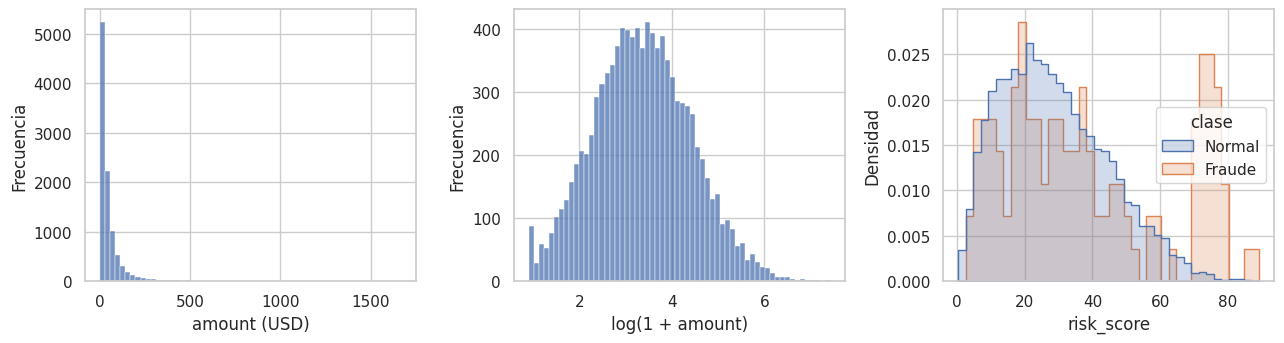

In [7]:
df["amount_log"] = np.log1p(df["amount"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(df["amount"], bins=60, ax=axes[0])
axes[0].set_xlabel("amount (USD)"); axes[0].set_ylabel("Frecuencia")
sns.histplot(df["amount_log"], bins=60, ax=axes[1])
axes[1].set_xlabel("log(1 + amount)"); axes[1].set_ylabel("Frecuencia")
sns.histplot(data=df.assign(clase=df["is_fraud"].map({0: "Normal", 1: "Fraude"})), x="risk_score",
             hue="clase", hue_order=["Normal", "Fraude"], bins=40, stat="density",
             common_norm=False, element="step", ax=axes[2])
axes[2].set_xlabel("risk_score"); axes[2].set_ylabel("Densidad")
savefig("fig_numericas")
plt.show()

In [8]:
# Diferencias entre clases: Mann-Whitney U (no paramétrica) + AUC univariada como índice de discriminación
filas = []
for col in ["amount", "risk_score"]:
    a = df.loc[df.is_fraud == 1, col]; b = df.loc[df.is_fraud == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas.append({"variable": col, "mediana_fraude": a.median(), "mediana_normal": b.median(),
                  "p_MannWhitney": f"{p:.2e}", "AUC_univariada": roc_auc_score(df.is_fraud, df[col])})
pd.DataFrame(filas)

,variable,mediana_fraude,mediana_normal,p_MannWhitney,AUC_univariada
0,amount,25.395,27.370,7.02e-01,0.490
1,risk_score,33.275,26.565,8.32e-05,0.602


> **Punto a discutir (posible fuga de información):** `risk_score` es un puntaje *ya calculado* cuyo origen no se documenta.
> Si se derivó parcialmente de la etiqueta, inflaría el rendimiento. Plan: entrenar los modelos **con y sin** `risk_score` y comparar (se hará en la Parte C).

**Hallazgo a verificar y reportar:** en el histograma de `risk_score`, los fraudes no siguen una sola distribución: una parte se parece a las transacciones normales y otra forma un grupo separado con puntajes altos (≈ 70–90). Con los datos de este dataset, ≈ 24 % de los fraudes tiene `risk_score` ≥ 65, frente a ≈ 1,7 % de las transacciones normales. Es la señal más fuerte del dataset y explica por qué la AUC univariada de `risk_score` es solo moderada (≈ 0,60): el resto de los fraudes es casi indistinguible por esta variable.

In [9]:
for t in (60, 65, 70):
    k = df["risk_score"] >= t
    print(f"risk_score >= {t}: {100*(df.loc[df.is_fraud==1,'risk_score']>=t).mean():.1f}% de los fraudes | "
          f"{100*(df.loc[df.is_fraud==0,'risk_score']>=t).mean():.2f}% de los normales | "
          f"precisión de la regla = {100*df.loc[k,'is_fraud'].mean():.1f}% ({k.sum()} transacciones)")

risk_score >= 60: 24.6% de los fraudes | 3.61% de los normales | precisión de la regla = 8.0% (387 transacciones)
risk_score >= 65: 23.8% de los fraudes | 1.68% de los normales | precisión de la regla = 15.3% (196 transacciones)
risk_score >= 70: 23.8% de los fraudes | 0.67% de los normales | precisión de la regla = 31.2% (96 transacciones)


### Variables categóricas: tasa de fraude por nivel (IC 95 % de Wilson) y prueba χ²

In [10]:
CAT = ["account_type", "category", "payment_method", "device_type"]

def tabla_fraude(col):
    g = df.groupby(col)["is_fraud"].agg(n="count", fraudes="sum")
    g["tasa_%"] = 100 * g["fraudes"] / g["n"]
    lo, hi = proportion_confint(g["fraudes"], g["n"], method="wilson")
    g["IC95_inf_%"], g["IC95_sup_%"] = 100 * lo, 100 * hi
    return g.sort_values("tasa_%", ascending=False)

for c in CAT:
    print(f"\n=== {c} ===")
    display(tabla_fraude(c))
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], df["is_fraud"]))
    print(f"chi2 = {chi2:.2f}, gl = {dof}, p-valor = {p:.3f}")


=== account_type ===


,n,fraudes,tasa_%,IC95_inf_%,IC95_sup_%
account_type,,,,,
Savings,3992,56,1.403,1.082,1.817
Credit Card,1453,20,1.376,0.893,2.117
Checking,4555,50,1.098,0.834,1.444


chi2 = 1.78, gl = 2, p-valor = 0.411

=== category ===


,n,fraudes,tasa_%,IC95_inf_%,IC95_sup_%
category,,,,,
Travel,822,13,1.582,0.927,2.687
Online Transfer,1029,16,1.555,0.959,2.511
Electronics,1018,15,1.473,0.895,2.417
Groceries,2515,34,1.352,0.969,1.883
Utilities,1220,15,1.230,0.746,2.019
Entertainment,962,10,1.040,0.566,1.903
Dining,1944,19,0.977,0.627,1.522
Healthcare,490,4,0.816,0.318,2.080


chi2 = 4.35, gl = 7, p-valor = 0.738

=== payment_method ===


,n,fraudes,tasa_%,IC95_inf_%,IC95_sup_%
payment_method,,,,,
Debit Card,3451,47,1.362,1.026,1.806
Credit Card,3602,47,1.305,0.983,1.731
Bank Transfer,977,11,1.126,0.630,2.005
UPI,1970,21,1.066,0.698,1.624


chi2 = 1.08, gl = 3, p-valor = 0.781

=== device_type ===


,n,fraudes,tasa_%,IC95_inf_%,IC95_sup_%
device_type,,,,,
Mobile,5472,73,1.334,1.062,1.674
POS Terminal,1034,13,1.257,0.736,2.139
ATM,965,12,1.244,0.713,2.161
Desktop,2529,28,1.107,0.767,1.596


chi2 = 0.72, gl = 3, p-valor = 0.869


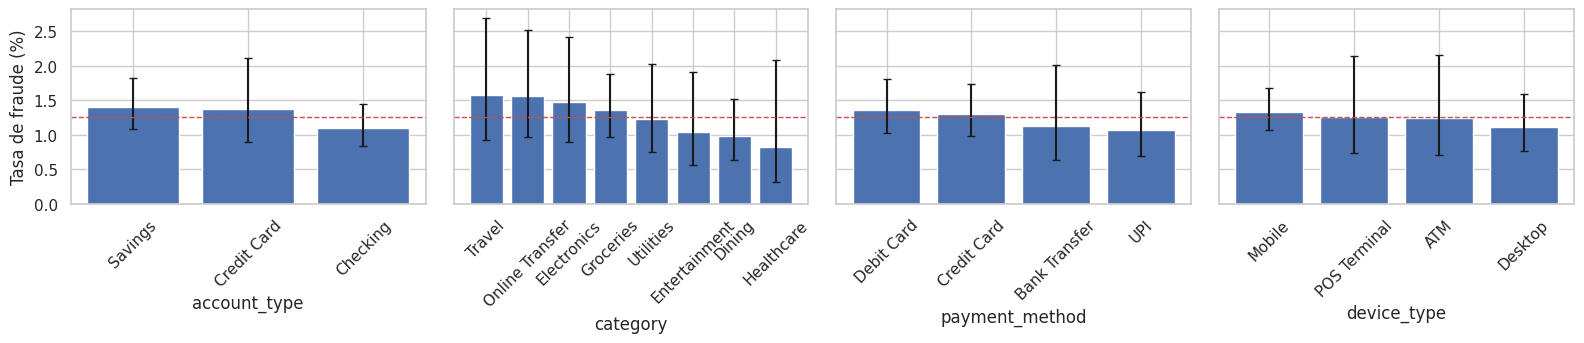

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
global_rate = 100 * df["is_fraud"].mean()
for ax, c in zip(axes, CAT):
    t = tabla_fraude(c).reset_index()
    err = [t["tasa_%"] - t["IC95_inf_%"], t["IC95_sup_%"] - t["tasa_%"]]
    ax.bar(t[c], t["tasa_%"], yerr=err, capsize=3, color="#4C72B0")
    ax.axhline(global_rate, color="#C44E52", ls="--", lw=1)
    ax.set_xlabel(c); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Tasa de fraude (%)")
savefig("fig_tasa_fraude_categoricas")
plt.show()

### Variable temporal

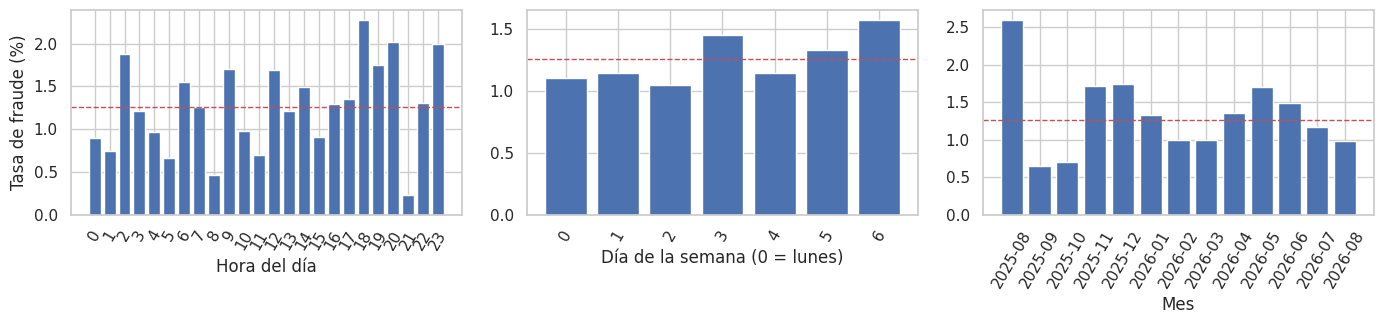

In [12]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.to_period("M").astype(str)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, c, xl in zip(axes, ["hour", "dayofweek", "month"], ["Hora del día", "Día de la semana (0 = lunes)", "Mes"]):
    r = df.groupby(c)["is_fraud"].mean() * 100
    ax.bar(r.index.astype(str), r.values, color="#4C72B0")
    ax.axhline(global_rate, color="#C44E52", ls="--", lw=1)
    ax.set_xlabel(xl); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("Tasa de fraude (%)")
savefig("fig_temporal")
plt.show()

In [13]:
# Prueba de permutación para variables temporales
df["franja"] = pd.cut(df["hour"], [-1, 5, 11, 17, 23],
                      labels=["00-05", "06-11", "12-17", "18-23"]).astype(str)

def chi2_stat(codes, y, k):
    n1 = np.bincount(codes, weights=y, minlength=k)   # fraudes por nivel
    n = np.bincount(codes, minlength=k)               # transacciones por nivel
    p = y.mean()
    e1, e0 = n * p, n * (1 - p)
    return ((n1 - e1) ** 2 / e1 + ((n - n1) - e0) ** 2 / e0).sum()

def test_permutacion(col, B=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    codes, niveles = pd.factorize(df[col]); k = len(niveles)
    y = df["is_fraud"].to_numpy(dtype=float)
    obs = chi2_stat(codes, y, k)
    sims = np.array([chi2_stat(codes, rng.permutation(y), k) for _ in range(B)])
    return obs, (1 + (sims >= obs).sum()) / (B + 1)

filas = []
for c in ["hour", "dayofweek", "month", "franja"]:
    obs, p = test_permutacion(c)
    exp_min = (df.groupby(c).size() * df["is_fraud"].mean()).min()
    filas.append({"variable": c, "niveles": df[c].nunique(),
                  "min_fraudes_esperados": round(exp_min, 1),
                  "chi2_obs": round(obs, 2), "p_permutacion": round(p, 3)})
pd.DataFrame(filas)

,variable,niveles,min_fraudes_esperados,chi2_obs,p_permutacion
0,hour,24,4.400,21.040,0.580
1,dayofweek,7,17.100,2.710,0.837
2,month,13,1.900,12.840,0.377
3,franja,4,31.000,3.400,0.336


### Estructura por usuario (relevante para la estrategia de validación)

In [14]:
por_usuario = df.groupby("user_id").agg(n_tx=("is_fraud", "size"), n_fraudes=("is_fraud", "sum"))
print("Usuarios:", len(por_usuario))
print("Transacciones por usuario:\n", por_usuario["n_tx"].describe().round(2).to_string())
print("\nUsuarios con al menos un fraude:", int((por_usuario["n_fraudes"] > 0).sum()))
print("Usuarios con más de un fraude:", int((por_usuario["n_fraudes"] > 1).sum()))

Usuarios: 2142
Transacciones por usuario:
 count   2,142.000
mean        4.670
std         2.580
min         1.000
25%         3.000
50%         4.000
75%         6.000
max        18.000

Usuarios con al menos un fraude: 124
Usuarios con más de un fraude: 2


### Relación entre variables (riesgo vs. canal/dispositivo/monto)

In [15]:
for c in ["device_type", "payment_method", "account_type", "category"]:
    print(f"\n--- risk_score medio por {c} ---")
    display(df.groupby(c)["risk_score"].agg(["count", "mean", "std"]))
rho, p = stats.spearmanr(df["amount"], df["risk_score"])
print(f"\nSpearman(amount, risk_score) = {rho:.3f} (p = {p:.3g})")


--- risk_score medio por device_type ---


,count,mean,std
device_type,,,
ATM,965,28.674,15.869
Desktop,2529,28.823,16.006
Mobile,5472,28.645,15.757
POS Terminal,1034,28.329,15.563



--- risk_score medio por payment_method ---


,count,mean,std
payment_method,,,
Bank Transfer,977,28.102,15.082
Credit Card,3602,28.518,15.874
Debit Card,3451,28.916,15.978
UPI,1970,28.748,15.749



--- risk_score medio por account_type ---


,count,mean,std
account_type,,,
Checking,4555,28.640,15.701
Credit Card,1453,28.720,15.687
Savings,3992,28.661,15.981



--- risk_score medio por category ---


,count,mean,std
category,,,
Dining,1944,28.807,15.624
Electronics,1018,27.745,15.744
Entertainment,962,28.109,15.792
Groceries,2515,28.827,15.921
Healthcare,490,28.222,15.636
Online Transfer,1029,28.790,16.022
Travel,822,29.206,16.047
Utilities,1220,28.978,15.670



Spearman(amount, risk_score) = 0.014 (p = 0.173)


## 2.3 Preprocesamiento y codificación (decisiones a documentar)

| Variable | Decisión | Justificación |
|---|---|---|
| `transaction_id`, `user_id` | Descartar como predictores | Identificadores sin significado predictivo |
| `currency` | Descartar | Constante (USD) |
| `amount` | `log1p` + estandarización | Distribución muy asimétrica (log-normal) |
| `risk_score` | Estandarización (con y sin la variable) | Posible fuga de información |
| `timestamp` | `hour` (codificación cíclica sen/cos), `is_weekend` | La hora es circular (23 → 0) |
| `account_type`, `category`, `payment_method`, `device_type` | One-hot | Baja cardinalidad, sin orden natural |
| Faltantes | Ninguno → sin imputación | Verificado arriba |

> Importante: escaladores y codificadores se ajustan **solo con el conjunto de entrenamiento de cada partición** (dentro de un `Pipeline`) para evitar fuga de datos.


Se descartaron transaction_id, user_id y currency como predictores. amount se transformó con log(1+x) y se estandarizó. De timestamp se derivaron la hora, con codificación cíclica (seno y coseno de 2πh/24), y un indicador de fin de semana. Las cuatro categóricas, de baja cardinalidad y sin orden natural, se codificaron con one-hot, lo que deja un espacio de 24 características. Los escaladores y codificadores se ajustan únicamente con el conjunto de entrenamiento de cada partición, dentro de un Pipeline, para evitar fuga de información. Como risk_score es un puntaje ya calculado cuyo origen no se documenta, existe riesgo de fuga, y por eso los modelos se evaluarán con y sin esa variable.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

NUM = ["amount_log", "risk_score", "hour_sin", "hour_cos", "is_weekend"]
CATS = ["account_type", "category", "payment_method", "device_type"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop=None), CATS),
])

X = df[NUM + CATS]
y = df["is_fraud"]

# Partición de ejemplo para ver cuántos fraudes quedan en test
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Entrenamiento: {len(y_tr):,} muestras, {y_tr.sum()} fraudes")
print(f"Test:          {len(y_te):,} muestras, {y_te.sum()} fraudes   <-- muy pocos: IC amplios")

Xt = preprocess.fit(X_tr).transform(X_tr)
print("Dimensión del espacio de características tras codificación:", Xt.shape[1])

Entrenamiento: 8,000 muestras, 101 fraudes
Test:          2,000 muestras, 25 fraudes   <-- muy pocos: IC amplios
Dimensión del espacio de características tras codificación: 24


## 2.4 Paradigma de aprendizaje (plantilla de redacción)

- **Paradigma:** aprendizaje supervisado, clasificación binaria (`is_fraud` ∈ {0, 1}).
- **Justificación:** se dispone de etiqueta de verdad, el objetivo es predecir una categoría, y el costo de un fraude no detectado es mayor que el de una falsa alarma.
- **Desafíos:** desbalance severo (~1,26 %), pocas muestras positivas (126), posible fuga por `risk_score`, señal débil en las categóricas.
- **Métricas previstas:** PR-AUC (principal), recall de fraude, precisión, F1, MCC, ROC-AUC y exactitud balanceada. _La exactitud simple no se usa como criterio: un modelo que nunca predice fraude obtiene ≈ 98,7 %._
- **Alternativa a mencionar:** detección de anomalías (no supervisada) como contraste.

---
# 3. Estado del arte

**Requisitos de la guía:** ≥ 4 artículos sobre el mismo problema (idealmente con la misma base de datos), preferiblemente de **revista** (Elsevier / IEEE; Springer tiene acceso limitado), **máximo 1 página**. Para cada uno: paradigma, técnica(s), metodología de validación, métricas (con definición matemática si no se vieron en clase) y resultados.



## Candidatos — artículos experimentales (prioridad para las 4 citas mínimas)

| # | Referencia | Tipo / venue | Por qué sirve para este proyecto | Verificado |
|---|---|---|---|---|
| E1 | Dal Pozzolo, Boracchi, Caelen, Alippi, Bontempi. *Credit Card Fraud Detection: A Realistic Modeling and a Novel Learning Strategy.* IEEE Trans. Neural Netw. Learn. Syst., 29(8), 3784–3797, 2018. DOI 10.1109/TNNLS.2017.2736643 | Revista IEEE | Referente del campo: formaliza el problema, discute desbalance y **métricas adecuadas para fraude**, y evalúa sobre transacciones reales | Título, autores, revista, vol./núm. |
| E2 | Correa Bahnsen, Aouada, Stojanovic, Ottersten. *Feature Engineering Strategies for Credit Card Fraud Detection.* Expert Syst. Appl., 51, 134–142, 2016. DOI 10.1016/j.eswa.2015.12.030 | Revista Elsevier | Ingeniería de características de **monto y hora** (muy relacionada con `timestamp`/`amount`) y su efecto en modelos | Título, revista, vol., págs., DOI |
| E3 | Dal Pozzolo, Caelen, Le Borgne, Waterschoot, Bontempi. *Learned lessons in credit card fraud detection from a practitioner perspective.* Expert Syst. Appl., 41(10), 4915–4928, 2014. | Revista Elsevier | Compara clasificadores y estrategias de muestreo; discute métricas con desbalance | Título, revista, vol./págs. (de listas de referencias) |
| E4 | Carcillo, Le Borgne, Caelen, Kessaci, Oblé, Bontempi. *Combining unsupervised and supervised learning in credit card fraud detection.* Information Sciences. | Revista Elsevier | Híbrido supervisado + no supervisado (contraste con detección de anomalías) | Título, autores, revista. **Volumen/año: confirmar** (fuentes con datos distintos) |
| E5 | Gostkowski, Krasnodebski, Niedziolka. *Credit Card Fraud Detection Using Machine Learning Techniques.* European Research Studies Journal, XXVII(2), 571–585, 2024. DOI 10.35808/ersj/3804 | Revista (Scopus-indexada, de menor impacto) | Compara RNA, árbol y bosque aleatorio con SMOTE/sobre/submuestreo usando F1 | Resumen, revista, DOI |

## Candidatos — revisiones sistemáticas (apoyo para contexto y para justificar decisiones)

| # | Referencia | Venue | Uso sugerido |
|---|---|---|---|
| R1 | Cherif, Badhib, Ammar, Alshehri, Kalkatawi, Imine. *Credit card fraud detection in the era of disruptive technologies: A systematic review.* J. King Saud Univ. – Comput. Inf. Sci., 35(1), 145–174, 2023 | Revista (Elsevier) | Contexto; resume 40 artículos (2015–2021), desbalance e ingeniería de características |
| R2 | Kalid, Khor, Ng, Tong. *Detecting Frauds and Payment Defaults on Credit Card Data Inherited With Imbalanced Class Distribution and Overlapping Class Problems: A Systematic Review.* IEEE Access, 2024 | Revista IEEE | Justifica el uso de ensambles, muestreo y **métricas que evalúan por separado fraude y normales** (volumen/págs.: confirmar) |
| R3 | *A Systematic Review of Machine Learning in Credit Card Fraud Detection Under Original Class Imbalance.* Computers (MDPI), 14(10), 437, 2025 | Revista MDPI | Revisa enfoques **sin** sobre/submuestreo (autores: completar) |

> Ojo con el criterio de la guía: _"artículos que hayan abordado el mismo problema"_. Las revisiones (R1–R3) ayudan, pero los **4 mínimos** deberían ser preferiblemente experimentales (E1–E5). Evita conferencias/tesis salvo que no tengas alternativa.



---
# 4. Entrenamiento y evaluación

Pendiente para la siguiente entrega. Se deja la estructura para no rediseñar después.

**Requisitos de la guía:** metodología de validación; tabla de hiperparámetros con la malla de cada modelo; **≥ 5 modelos** que incluyan: (1) paramétrico (discriminantes gaussianos o regresión logística), (2) no paramétrico, (3) ensamble de árboles, (4) red neuronal artificial, (5) SVM; métricas justificadas; resultados con **intervalos de confianza** y con resultados de **entrenamiento, validación y test**.

---
# 5. Reducción de dimensión

**Requisitos de la guía:**
1. **5.1 Análisis individual de variables:** correlación y/o índice de discriminación por variable; identificar candidatas a eliminar. _(Ya hay avances en la Parte A: AUC univariada, χ², Mann-Whitney.)_
2. **5.2 PCA:** menos componentes que variables originales; reevaluar los **2 mejores modelos** de la sección 4; justificar el criterio de nº de componentes (varianza explicada, codo, validación…); tabla con **% de reducción** y demás métricas.
3. **5.3 UMAP:** igual que PCA, con UMAP.
4. **Reajustar hiperparámetros** en cada nuevo espacio de características.
5. **Discusión y conclusiones** comparando con el estado del arte.